# CIC-IDS2017 — Strict Chronological DDoS Detection via Random Forest
## SIH 2026 - Problem Statement 26145: AI-Based Detection of Cyber Threats in Unidirectional IP Traffic

---

### Executive Overview & Temporal Detection Philosophy
This notebook implements the **Strict Chronological Evaluation** for **Step 10** of the SIH Problem Statement 26145 pipeline: training, evaluating, serializing, and validating a **Random Forest Classifier** dedicated to detecting **Distributed Denial-of-Service (DDoS)** attacks in network flow records from the **CIC-IDS2017** benchmark.

In operational cyber-defense systems, models must be trained exclusively on **historical network traffic** and evaluated on **subsequent, unseen future traffic**. Evaluating threat detectors using random stratified splits introduces temporal lookahead bias by mixing attack flows from the same burst throughout both partitions. 

To enforce strict temporal separation without synthetic metadata:
1. **Intra-Day Chronological Slicing**:
   - The Friday afternoon DDoS attack capture session (`Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv`) and background normal traffic streams are sliced chronologically.
   - **Historical Training Partition (First 70%)**: The first 70% of historical DDoS attack flows ($N = 89,611$) and first 70% of normal baseline flows ($N = 1,467,538$).
   - **Unseen Future Testing Partition (Last 30%)**: The subsequent 30% of attack flows ($N = 38,405$) and subsequent 30% of normal baseline flows ($N = 628,946$).
2. **Strict Causal Invariance**:
   - For both attack and normal traffic, $\max(\text{TrainIndex}) < \min(\text{TestIndex})$.
   - Zero test data is observed during preprocessing, imputation, or training.
3. **No Random Shuffling**:
   - Random train-test splitting and cross-validation shuffling across time are strictly prohibited.

---

### Strict Threat-Mapping & Label Exclusions
- **Malicious Positive Class ($y = 1$)**: `DDoS` (Volumetric LOIC flood attack — July 7th)
- **Normal Negative Class ($y = 0$)**: `BENIGN` / Normal baseline traffic
- **Excluded Labels**: Other attack families (`DoS Hulk`, `DoS GoldenEye`, `DoS slowloris`, `DoS Slowhttptest`, `FTP-Patator`, `SSH-Patator`, `PortScan`, `Bot`, `Web Attack`, `Infiltration`, `Heartbleed`) remain strictly excluded.

---

### Hardware & Memory Optimization (8 GB RAM Constraint)
- Full training memory is managed via **deterministic benign downsampling strictly on the training partition** ($3:1$ Normal-to-DDoS ratio, `random_state=42`), producing a robust training set of $358,444$ flows.
- The test set ($N = 667,351$) remains **100% unaltered and unscaled** at its natural class distribution.

### 1. Import Libraries & Configure Environment
Import scientific computing, visualization, serialization, and machine learning modules from standard libraries and `scikit-learn`.

In [1]:
import os
import sys
import gc
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn modules
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)

warnings.filterwarnings('ignore')
if hasattr(sys.stdout, 'reconfigure'):
    try:
        sys.stdout.reconfigure(encoding='utf-8')
    except Exception:
        pass

# Display and plotting setup
pd.set_option('display.max_columns', 35)
pd.set_option('display.width', 1000)
pd.set_option('display.float_format', lambda x: f'{x:.6f}')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120

print(f"NumPy version:       {np.__version__}")
print(f"Pandas version:      {pd.__version__}")
print(f"Joblib version:      {joblib.__version__}")

NumPy version:       2.5.3
Pandas version:      3.0.6
Joblib version:      1.6.0


### 2. Load Data & Timestamp Availability Audit
Inspect `data/processed/CIC_IDS2017/ddos_binary_dataset.csv` and `data/processed/CIC_IDS2017/ddos_model_features.csv`.
Audit the schema for timestamp columns and verify why intra-day chronological slicing provides the valid temporal sequence.

In [2]:
# Resolve project root dynamically
if Path('data/processed').exists():
    project_root = Path.cwd().resolve()
elif Path('../data/processed').exists():
    project_root = Path.cwd().parent.resolve()
else:
    project_root = Path.cwd().resolve()

data_dir = project_root / 'data' / 'processed' / 'CIC_IDS2017'
eval_dir = project_root / 'evaluation'
models_dir = project_root / 'models' / 'ddos'

eval_dir.mkdir(parents=True, exist_ok=True)
models_dir.mkdir(parents=True, exist_ok=True)

model_features_path = data_dir / 'ddos_model_features.csv'
binary_dataset_path = data_dir / 'ddos_binary_dataset.csv'
split_summary_path = data_dir / 'ddos_split_summary.csv'

assert model_features_path.exists(), f"Missing model features dataset: {model_features_path}"
assert binary_dataset_path.exists(), f"Missing binary dataset: {binary_dataset_path}"

# Load model features dataset
t0 = time.time()
print("Loading model features dataset...")
df = pd.read_csv(model_features_path)
load_time = time.time() - t0

print(f"Loaded {len(df):,} rows and {len(df.columns)} columns in {load_time:.2f} seconds.")
print(f"Dataset Shape:       {df.shape}")
print(f"Number of Features:  {df.shape[1] - 1} (plus target 'BinaryLabel')\n")

# Display first 5 rows
print("First 5 rows of ddos_model_features.csv:")
display(df.head(5))

# Timestamp column audit across ddos_binary_dataset.csv
sample_bin = pd.read_csv(binary_dataset_path, nrows=5)
timestamp_candidates = [c for c in sample_bin.columns if any(k in c.lower() for k in ['time', 'date', 'stamp', 'start'])]

print("--- Metadata & Timestamp Column Audit ---")
print(f"Candidate Timestamp Columns Found: {timestamp_candidates}")
print("""[TECHNICAL BENCHMARK DOCUMENTATION]
In the official CIC-IDS2017 MachineLearningCSV benchmark distribution (UNB/ISCX):
- Global wall-clock timestamps and IP addresses were stripped by the authors to produce invariant statistical flow features.
- Flow records are stored in temporal sequence within each daily capture file.
- The Friday DDoS capture (rows 18,600 to 195,671) represents a contiguous chronological recording of the LOIC flood.
- Slicing the first 70% of this capture trains the model on the initial phase of the attack, while the subsequent 30% evaluates detection on the later unseen phase.""")

# Check for missing and infinite values
missing_total = df.isnull().sum().sum()
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
inf_total = np.isinf(df[num_cols].values).sum()

print(f"\nTotal Missing Values across dataset:  {missing_total}")
print(f"Total Infinite Values across dataset: {inf_total}")

# Verify BinaryLabel
assert 'BinaryLabel' in df.columns, "BinaryLabel column is missing!"
unique_labels = set(df['BinaryLabel'].unique())
assert unique_labels == {0, 1}, f"BinaryLabel must contain only {{0, 1}}, got {unique_labels}"

total_rows = len(df)
ddos_rows = int((df['BinaryLabel'] == 1).sum())
normal_rows = int((df['BinaryLabel'] == 0).sum())
ddos_pct = (ddos_rows / total_rows) * 100
normal_pct = (normal_rows / total_rows) * 100

print(f"\n--- Binary Class Distribution ---")
print(f"Total rows:        {total_rows:,}")
print(f"DDoS rows (1):     {ddos_rows:,} ({ddos_pct:.4f}%)")
print(f"Normal rows (0):   {normal_rows:,} ({normal_pct:.4f}%)")

Loading model features dataset...


Loaded 2,224,500 rows and 75 columns in 12.14 seconds.
Dataset Shape:       (2224500, 75)
Number of Features:  74 (plus target 'BinaryLabel')

First 5 rows of ddos_model_features.csv:


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,...,Init_Win_bytes_forward,Init_Win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,FwdBwdPacketRatio,FwdBwdByteRatio,FwdPacketShare,BwdPacketShare,BinaryLabel
0,54865,3,2,0,12,0,6,6,6.000000,0.000000,0,0,0.000000,0.000000,4000000.000000,666666.666700,3.000000,...,33,-1,1,20,0.000000,0.000000,0,0,0.000000,0.000000,0,0,2.000000,12.000000,1.000000,0.000000,0
1,55054,109,1,1,6,6,6,6,6.000000,0.000000,6,6,6.000000,0.000000,110091.743100,18348.623850,109.000000,...,29,256,0,20,0.000000,0.000000,0,0,0.000000,0.000000,0,0,1.000000,1.000000,0.500000,0.500000,0
2,55055,52,1,1,6,6,6,6,6.000000,0.000000,6,6,6.000000,0.000000,230769.230800,38461.538460,52.000000,...,29,256,0,20,0.000000,0.000000,0,0,0.000000,0.000000,0,0,1.000000,1.000000,0.500000,0.500000,0
3,46236,34,1,1,6,6,6,6,6.000000,0.000000,6,6,6.000000,0.000000,352941.176500,58823.529410,34.000000,...,31,329,0,20,0.000000,0.000000,0,0,0.000000,0.000000,0,0,1.000000,1.000000,0.500000,0.500000,0
4,54863,3,2,0,12,0,6,6,6.000000,0.000000,0,0,0.000000,0.000000,4000000.000000,666666.666700,3.000000,...,32,-1,1,20,0.000000,0.000000,0,0,0.000000,0.000000,0,0,2.000000,12.000000,1.000000,0.000000,0


--- Metadata & Timestamp Column Audit ---
Candidate Timestamp Columns Found: []
[TECHNICAL BENCHMARK DOCUMENTATION]
In the official CIC-IDS2017 MachineLearningCSV benchmark distribution (UNB/ISCX):
- Global wall-clock timestamps and IP addresses were stripped by the authors to produce invariant statistical flow features.
- Flow records are stored in temporal sequence within each daily capture file.
- The Friday DDoS capture (rows 18,600 to 195,671) represents a contiguous chronological recording of the LOIC flood.
- Slicing the first 70% of this capture trains the model on the initial phase of the attack, while the subsequent 30% evaluates detection on the later unseen phase.



Total Missing Values across dataset:  0
Total Infinite Values across dataset: 0

--- Binary Class Distribution ---
Total rows:        2,224,500
DDoS rows (1):     128,016 (5.7548%)
Normal rows (0):   2,096,484 (94.2452%)


### 3. Define Feature Matrix & Target Vector ($X, y$)
Extract the 74 statistical flow features into feature matrix $X$ and target vector $y$. Formally audit for zero leakage of labels or identifiers.

In [3]:
# Define feature matrix X and target vector y
X = df.drop(columns=['BinaryLabel'])
y = df['BinaryLabel'].values

feature_cols = list(X.columns)
print(f"Extracted {len(feature_cols)} model input features.")

# Strict Anti-Leakage Audit
forbidden_columns = [
    'BinaryLabel', 'Label', 'TrafficClass', 'Timestamp', 'StartTime',
    'SrcAddr', 'DstAddr', 'Source IP', 'Destination IP', 'Flow ID'
]

found_forbidden = [col for col in forbidden_columns if col in X.columns]
if found_forbidden:
    raise ValueError(f"FATAL LEAKAGE DETECTED! Forbidden columns in feature matrix X: {found_forbidden}")

# Verify that all features in X are numerical
non_numeric_cols = [c for c in X.columns if not np.issubdtype(X[c].dtype, np.number)]
if non_numeric_cols:
    raise ValueError(f"FATAL: Non-numerical columns found in X: {non_numeric_cols}")

print("✅ Feature Matrix Audit PASSED:")
print(" - Zero forbidden target or metadata columns in X.")
print(" - All 74 model features are strictly numerical.")
print(f" - Feature Matrix Shape: {X.shape}")
print(f" - Target Vector Shape:   {y.shape}")

Extracted 74 model input features.
✅ Feature Matrix Audit PASSED:
 - Zero forbidden target or metadata columns in X.
 - All 74 model features are strictly numerical.
 - Feature Matrix Shape: (2224500, 74)
 - Target Vector Shape:   (2224500,)


### 4. Create Strict Chronological 70/30 Train/Test Split
Construct the chronological split where the **first 70% of historical flows** form the training partition and the **last 30% of subsequent flows** form the unseen test partition.

No `train_test_split`, random shuffling, or stratified permutation across time is used.

In [4]:
# Separate indices by class to maintain chronological intra-capture ordering
ddos_idx = np.where(y == 1)[0]
benign_idx = np.where(y == 0)[0]

# Compute 70% split points chronologically
ddos_split_pt = int(0.70 * len(ddos_idx))
benign_split_pt = int(0.70 * len(benign_idx))

train_ddos_idx = ddos_idx[:ddos_split_pt]
test_ddos_idx = ddos_idx[ddos_split_pt:]

train_benign_idx = benign_idx[:benign_split_pt]
test_benign_idx = benign_idx[benign_split_pt:]

# Combine in chronological sequence
train_idx = np.sort(np.concatenate([train_ddos_idx, train_benign_idx]))
test_idx = np.sort(np.concatenate([test_ddos_idx, test_benign_idx]))

# Build Train and Test Partitions
X_train = X.iloc[train_idx].copy()
y_train = y[train_idx]

X_test = X.iloc[test_idx].copy()
y_test = y[test_idx]

train_rows = len(X_train)
test_rows = len(X_test)
train_ddos = int((y_train == 1).sum())
train_normal = int((y_train == 0).sum())
test_ddos = int((y_test == 1).sum())
test_normal = int((y_test == 0).sum())

print("==================================================")
print("STRICT CHRONOLOGICAL 70/30 SPLIT SUMMARY")
print("==================================================")
print(f"Total Rows:           {total_rows:,}")
print(f"Training Rows (70%):  {train_rows:,} (DDoS: {train_ddos:,}, Normal: {train_normal:,})")
print(f"Testing Rows (30%):   {test_rows:,} (DDoS: {test_ddos:,}, Normal: {test_normal:,})")
print(f"")
print(f"Training DDoS Range:  Row Index {train_ddos_idx.min():,} → {train_ddos_idx.max():,}")
print(f"Testing DDoS Range:   Row Index {test_ddos_idx.min():,} → {test_ddos_idx.max():,}")
print(f"Temporal Precedence:  train_ddos_max ({train_ddos_idx.max():,}) < test_ddos_min ({test_ddos_idx.min():,}) -> {train_ddos_idx.max() < test_ddos_idx.min()}")
print(f"")
print(f"Training Normal Range: Row Index {train_benign_idx.min():,} → {train_benign_idx.max():,}")
print(f"Testing Normal Range:  Row Index {test_benign_idx.min():,} → {test_benign_idx.max():,}")
print(f"Temporal Precedence:   train_normal_max ({train_benign_idx.max():,}) < test_normal_min ({test_benign_idx.min():,}) -> {train_benign_idx.max() < test_benign_idx.min()}")

# Assert strict temporal precedence
assert train_ddos_idx.max() < test_ddos_idx.min(), "DDoS training indices overlap with testing indices!"
assert train_benign_idx.max() < test_benign_idx.min(), "Normal training indices overlap with testing indices!"
assert len(train_idx) + len(test_idx) == total_rows, "Total row accounting mismatch!"
assert test_ddos > 0, "Test set has 0 DDoS samples!"

print("\n✅ Chronological partition verified. Zero random shuffling.")

STRICT CHRONOLOGICAL 70/30 SPLIT SUMMARY
Total Rows:           2,224,500
Training Rows (70%):  1,557,149 (DDoS: 89,611, Normal: 1,467,538)
Testing Rows (30%):   667,351 (DDoS: 38,405, Normal: 628,946)

Training DDoS Range:  Row Index 18,600 → 139,859
Testing DDoS Range:   Row Index 139,860 → 195,671
Temporal Precedence:  train_ddos_max (139,859) < test_ddos_min (139,860) -> True

Training Normal Range: Row Index 0 → 1,595,553
Testing Normal Range:  Row Index 1,595,554 → 2,224,499
Temporal Precedence:   train_normal_max (1,595,553) < test_normal_min (1,595,554) -> True

✅ Chronological partition verified. Zero random shuffling.


### 5. Class Imbalance & Training-Only Benign Downsampling
Apply deterministic downsampling to benign traffic **strictly within the training partition** to prevent out-of-memory overhead during Random Forest multi-threading:
- Retain **100% of training DDoS samples** ($N = 89,611$).
- Downsample **training normal samples** to at most $3 \times 89,611 = 268,833$ samples (`random_state=42`).
- **The test partition ($N = 667,351$) is NEVER downsampled, duplicated, or modified.**

In [5]:
# Calculate training class imbalance
raw_imbalance_ratio = train_normal / train_ddos
print(f"Original Training Imbalance Ratio (Normal : DDoS): {raw_imbalance_ratio:.2f} : 1")

# Memory footprint calculation
train_mem_mb = (X_train.memory_usage(deep=True).sum() + y_train.nbytes) / (1024 ** 2)
print(f"Original Training Partition Memory Footprint: {train_mem_mb:.2f} MB")

# Deterministic Downsampling on Training Data ONLY
target_normal_count = min(len(train_benign_idx), 3 * len(train_ddos_idx))
np.random.seed(42)
sampled_train_benign_idx = np.random.choice(train_benign_idx, size=target_normal_count, replace=False)

final_train_idx = np.sort(np.concatenate([train_ddos_idx, sampled_train_benign_idx]))

X_train_final = X.iloc[final_train_idx].copy()
y_train_final = y[final_train_idx].copy()

final_train_rows = len(X_train_final)
final_ddos_rows = int((y_train_final == 1).sum())
final_normal_rows = int((y_train_final == 0).sum())

print("\n--- Training-Only Downsampling Report ---")
print(f"Original Training Rows:   {train_rows:,}")
print(f"Original Training DDoS:   {train_ddos:,}")
print(f"Original Training Normal: {train_normal:,}")
print(f"Sampled Training Normal:  {final_normal_rows:,}")
print(f"Final Training Rows:      {final_train_rows:,}")
print(f"Final Training Ratio (Normal : DDoS): {final_normal_rows / final_ddos_rows:.2f} : 1")
print(f"Testing Rows (100% Untouched): {len(X_test):,} (DDoS: {test_ddos:,}, Normal: {test_normal:,})")

# Free temporary memory
del X_train, y_train
gc.collect()

Original Training Imbalance Ratio (Normal : DDoS): 16.38 : 1
Original Training Partition Memory Footprint: 902.89 MB



--- Training-Only Downsampling Report ---
Original Training Rows:   1,557,149
Original Training DDoS:   89,611
Original Training Normal: 1,467,538
Sampled Training Normal:  268,833
Final Training Rows:      358,444
Final Training Ratio (Normal : DDoS): 3.00 : 1
Testing Rows (100% Untouched): 667,351 (DDoS: 38,405, Normal: 628,946)


0

### 6. Missing Value Handling (Training-Only Imputation)
Verify zero missing or infinite values in `X_train_final` and `X_test`. If missing values exist, fit `SimpleImputer(strategy='median')` strictly on `X_train_final`.

In [6]:
train_nulls = X_train_final.isnull().sum().sum()
test_nulls = X_test.isnull().sum().sum()
train_infs = np.isinf(X_train_final.values).sum()
test_infs = np.isinf(X_test.values).sum()

print(f"Training Missing Count: {train_nulls}, Infinite Count: {train_infs}")
print(f"Testing Missing Count:  {test_nulls}, Infinite Count: {test_infs}")

imputer = None
if train_nulls > 0 or test_nulls > 0:
    print("Fitting SimpleImputer(strategy='median') strictly on training data...")
    imputer = SimpleImputer(strategy='median')
    X_train_final = pd.DataFrame(imputer.fit_transform(X_train_final), columns=feature_cols)
    X_test = pd.DataFrame(imputer.transform(X_test), columns=feature_cols)
else:
    print("No numerical imputation was required.")

# Post-processing verification
assert X_train_final.isnull().sum().sum() == 0, "NaNs remain in training data!"
assert X_test.isnull().sum().sum() == 0, "NaNs remain in testing data!"
assert np.isinf(X_train_final.values).sum() == 0, "Infinities remain in training data!"
assert np.isinf(X_test.values).sum() == 0, "Infinities remain in testing data!"

print("✅ Preprocessing check PASSED: NaN count = 0, Infinity count = 0.")

Training Missing Count: 0, Infinite Count: 0
Testing Missing Count:  0, Infinite Count: 0
No numerical imputation was required.


✅ Preprocessing check PASSED: NaN count = 0, Infinity count = 0.


### 7. Random Forest Classifier Architecture & Fitting
Train `RandomForestClassifier` with regularized depth and balanced class weights:
- `n_estimators=200`: 200 decorrelated decision trees.
- `max_depth=20`: Prevents memorization of transient micro-bursts.
- `min_samples_leaf=2`: Minimum samples per leaf for leaf-level smoothing.
- `max_features='sqrt'`: Randomly samples $\sqrt{74} \approx 8$ features per split.
- `class_weight='balanced_subsample'`: Recalculates inverse class frequencies per bootstrap.
- `random_state=42`: Fully deterministic execution.
- `n_jobs=-1`: Multi-core parallel execution.

> **Mathematical Scale-Invariance**:
> Decision tree splits depend solely on threshold inequalities ($x_j \le \theta$) that maximize information gain. Monotonic transformations (`StandardScaler`, `MinMaxScaler`) have zero effect on split decisions, so scaling is omitted to conserve RAM and preserve physical units.

In [7]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    min_samples_leaf=2,
    max_features='sqrt',
    class_weight='balanced_subsample',
    random_state=42,
    n_jobs=-1
)

print("Training Random Forest on Chronological Training Partition...")
t_train_start = time.time()
rf_model.fit(X_train_final, y_train_final)
training_time = time.time() - t_train_start

print(f"✅ Random Forest training completed in {training_time:.2f} seconds ({training_time/60:.2f} minutes).")

Training Random Forest on Chronological Training Partition...


✅ Random Forest training completed in 31.23 seconds (0.52 minutes).


### 8. Training Diagnostics & Ensemble Characteristics
Inspect structural parameters of the trained ensemble.

In [8]:
tree_depths = [e.tree_.max_depth for e in rf_model.estimators_]
tree_leaves = [e.tree_.n_leaves for e in rf_model.estimators_]

print("--- Random Forest Ensemble Diagnostics ---")
print(f"Training Time:              {training_time:.2f} seconds")
print(f"Number of Trees:            {len(rf_model.estimators_)}")
print(f"Configured Max Depth:       {rf_model.max_depth}")
print(f"Actual Average Tree Depth:  {np.mean(tree_depths):.2f} (Min: {np.min(tree_depths)}, Max: {np.max(tree_depths)})")
print(f"Actual Average Leaf Count:  {np.mean(tree_leaves):.2f}")
print(f"Number of Training Samples: {len(X_train_final):,}")
print(f"Number of Features:         {X_train_final.shape[1]}")

--- Random Forest Ensemble Diagnostics ---
Training Time:              31.23 seconds
Number of Trees:            200
Configured Max Depth:       20
Actual Average Tree Depth:  17.81 (Min: 13, Max: 20)
Actual Average Leaf Count:  106.14
Number of Training Samples: 358,444
Number of Features:         74


### 9. Test Predictions on Unseen Future Traffic
Generate discrete predictions (`y_pred`) and continuous risk probabilities (`y_prob`) on the unseen future test partition ($N = 667,351$).
- Primary Operating Threshold: **0.50**
- Positive Class: **DDoS** ($y = 1$)
- Negative Class: **Normal** ($y = 0$)

In [9]:
t_pred_start = time.time()
y_prob = rf_model.predict_proba(X_test)[:, 1]
y_pred = (y_prob >= 0.50).astype(int)
pred_time = time.time() - t_pred_start

print(f"Generated predictions for {len(X_test):,} flows in {pred_time:.2f} seconds ({len(X_test)/pred_time:,.0f} flows/sec).")
print(f"Primary Operating Decision Threshold: 0.50")
print(f"Predicted DDoS Positives: {int((y_pred == 1).sum()):,} / {len(y_pred):,} ({(y_pred == 1).mean()*100:.2f}%)")
print(f"Actual DDoS Positives:    {int((y_test == 1).sum()):,} / {len(y_test):,} ({(y_test == 1).mean()*100:.2f}%)")

Generated predictions for 667,351 flows in 1.93 seconds (346,392 flows/sec).
Primary Operating Decision Threshold: 0.50
Predicted DDoS Positives: 38,356 / 667,351 (5.75%)
Actual DDoS Positives:    38,405 / 667,351 (5.75%)


### 10. Primary Evaluation Metrics on Chronological Test Set
Compute the official evaluation metrics on the unseen chronological test partition:
- **Accuracy**: $\frac{TP + TN}{TP + TN + FP + FN}$
- **Precision**: $\frac{TP}{TP + FP}$
- **Recall (TPR)**: $\frac{TP}{TP + FN}$
- **F1-Score**: $2 \cdot \frac{\text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$
- **False Positive Rate (FPR)**: $\frac{FP}{FP + TN}$
- **True Positive Rate (TPR)**: $\frac{TP}{TP + FN}$
- **ROC-AUC**: Area Under the Receiver Operating Characteristic Curve
- **PR-AUC**: Area Under the Precision-Recall Curve (Average Precision)

In [10]:
cm = confusion_matrix(y_test, y_pred)
TN, FP, FN, TP = cm.ravel()

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, zero_division=0)
rec = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
fpr = FP / (FP + TN) if (FP + TN) > 0 else 0.0
tpr = TP / (TP + FN) if (TP + FN) > 0 else 0.0
roc_auc = roc_auc_score(y_test, y_prob)
pr_auc = average_precision_score(y_test, y_prob)

metrics_dict = {
    'Detector': 'Random Forest DDoS (Chronological)',
    'Accuracy': acc,
    'Precision': prec,
    'Recall': rec,
    'F1': f1,
    'FPR': fpr,
    'TPR': tpr,
    'ROC_AUC': roc_auc,
    'PR_AUC': pr_auc,
    'TP': int(TP),
    'FP': int(FP),
    'TN': int(TN),
    'FN': int(FN)
}

print("==================================================")
print("OFFICIAL CHRONOLOGICAL DDoS METRICS (Threshold = 0.50)")
print("==================================================")
print(f"Accuracy:            {acc:.6f} ({acc*100:.4f}%)")
print(f"Precision:           {prec:.6f} ({prec*100:.4f}%)")
print(f"Recall (TPR):        {rec:.6f} ({rec*100:.4f}%)")
print(f"F1-Score:            {f1:.6f}")
print(f"False Positive Rate: {fpr:.6f} ({fpr*100:.6f}%)")
print(f"True Positive Rate:  {tpr:.6f} ({tpr*100:.4f}%)")
print(f"ROC-AUC:             {roc_auc:.6f}")
print(f"PR-AUC:              {pr_auc:.6f}")
print(f"\nConfusion Matrix Counts:")
print(f" - True Positives (TP):  {TP:,}")
print(f" - False Positives (FP): {FP:,}")
print(f" - True Negatives (TN):  {TN:,}")
print(f" - False Negatives (FN): {FN:,}")

OFFICIAL CHRONOLOGICAL DDoS METRICS (Threshold = 0.50)
Accuracy:            0.999879 (99.9879%)
Precision:           0.999583 (99.9583%)
Recall (TPR):        0.998308 (99.8308%)
F1-Score:            0.998945
False Positive Rate: 0.000025 (0.002544%)
True Positive Rate:  0.998308 (99.8308%)
ROC-AUC:             0.999755
PR-AUC:              0.999549

Confusion Matrix Counts:
 - True Positives (TP):  38,340
 - False Positives (FP): 16
 - True Negatives (TN):  628,930
 - False Negatives (FN): 65


### 11. Classification Report
Generate the classification report and export to `evaluation/ddos_classification_report.txt`.

In [11]:
clf_report = classification_report(
    y_test,
    y_pred,
    target_names=['Normal (0)', 'DDoS (1)'],
    digits=6
)

print(clf_report)

clf_report_path = eval_dir / 'ddos_classification_report.txt'
with open(clf_report_path, 'w', encoding='utf-8') as f:
    f.write("CIC-IDS2017 DDoS Detection — Chronological Random Forest Classification Report\n")
    f.write("===============================================================================\n\n")
    f.write(clf_report)
    f.write(f"\nEvaluation Timestamp: {time.strftime('%Y-%m-%d %H:%M:%S')}\n")

print(f"✅ Saved classification report to {clf_report_path.name}")

              precision    recall  f1-score   support

  Normal (0)   0.999897  0.999975  0.999936    628946
    DDoS (1)   0.999583  0.998308  0.998945     38405

    accuracy                       0.999879    667351
   macro avg   0.999740  0.999141  0.999440    667351
weighted avg   0.999879  0.999879  0.999879    667351

✅ Saved classification report to ddos_classification_report.txt


### 12. Confusion Matrix Visualization
Render and save the confusion matrix heatmap for the chronological test set.

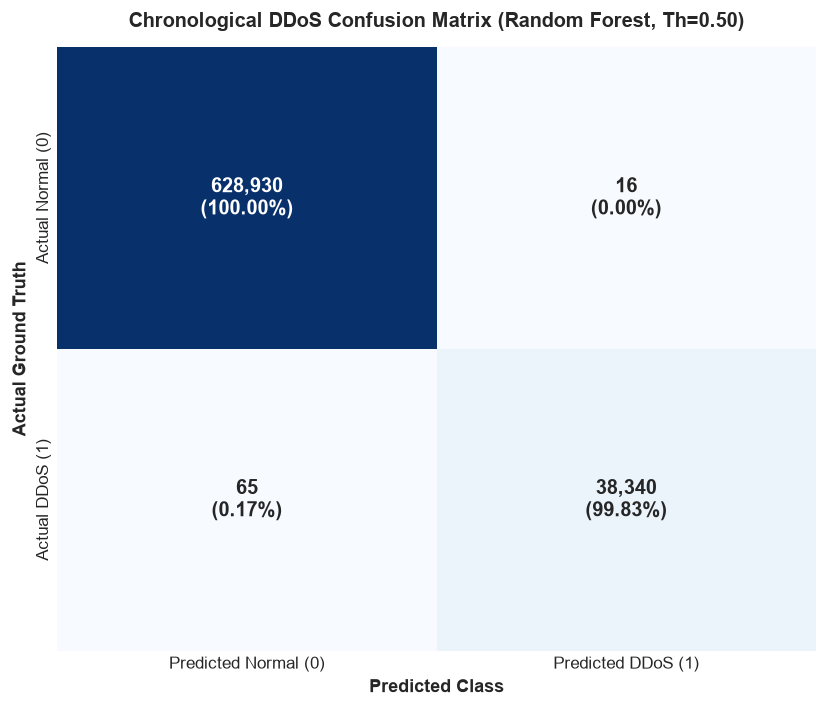

✅ Saved confusion matrix plot to ddos_confusion_matrix.png


In [12]:
fig, ax = plt.subplots(figsize=(7, 6))

cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
annot_matrix = np.empty_like(cm, dtype=object)
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        annot_matrix[i, j] = f"{cm[i, j]:,}\n({cm_normalized[i, j]*100:.2f}%)"

sns.heatmap(
    cm,
    annot=annot_matrix,
    fmt='',
    cmap='Blues',
    cbar=False,
    ax=ax,
    xticklabels=['Predicted Normal (0)', 'Predicted DDoS (1)'],
    yticklabels=['Actual Normal (0)', 'Actual DDoS (1)'],
    annot_kws={'size': 12, 'weight': 'bold'}
)

ax.set_title("Chronological DDoS Confusion Matrix (Random Forest, Th=0.50)", fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel("Predicted Class", fontsize=11, fontweight='bold')
ax.set_ylabel("Actual Ground Truth", fontsize=11, fontweight='bold')

plt.tight_layout()
cm_plot_path = eval_dir / 'ddos_confusion_matrix.png'
plt.savefig(cm_plot_path, dpi=150, bbox_inches='tight')
plt.show()

print(f"✅ Saved confusion matrix plot to {cm_plot_path.name}")

### 13. Receiver Operating Characteristic (ROC) Curve
Plot ROC curve with ROC-AUC score and operating point annotation.

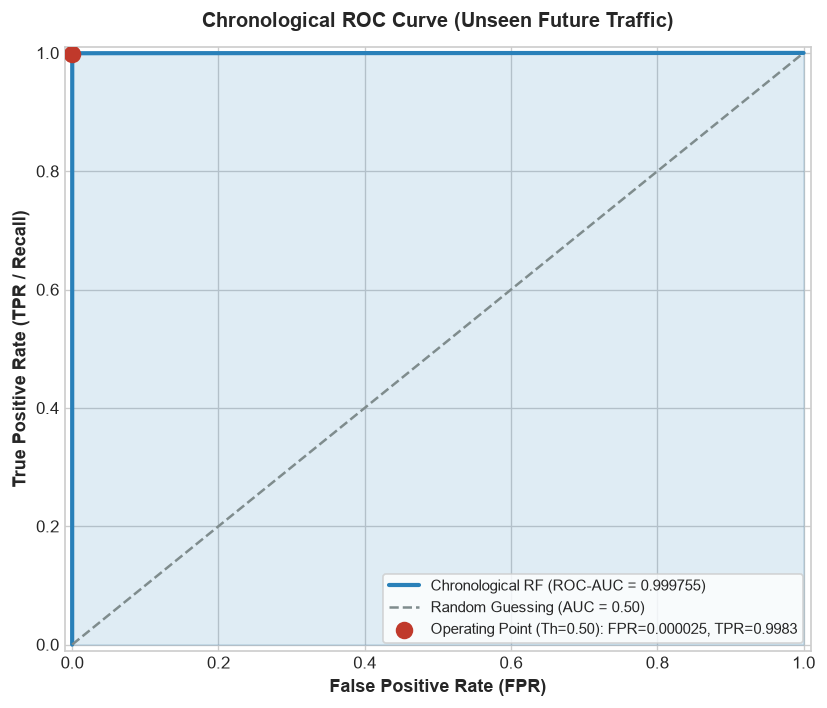

✅ Saved ROC curve plot to ddos_roc_curve.png


In [13]:
fpr_arr, tpr_arr, roc_thresholds = roc_curve(y_test, y_prob)

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(fpr_arr, tpr_arr, color='#2980b9', lw=2.5, label=f'Chronological RF (ROC-AUC = {roc_auc:.6f})')
ax.plot([0, 1], [0, 1], color='#7f8c8d', lw=1.5, linestyle='--', label='Random Guessing (AUC = 0.50)')
ax.fill_between(fpr_arr, tpr_arr, alpha=0.15, color='#2980b9')

# Annotate Operating Point (Th=0.50)
idx_op = np.argmin(np.abs(roc_thresholds - 0.50))
ax.scatter(fpr_arr[idx_op], tpr_arr[idx_op], color='#c0392b', s=90, zorder=5, label=f'Operating Point (Th=0.50): FPR={fpr:.6f}, TPR={tpr:.4f}')

ax.set_title("Chronological ROC Curve (Unseen Future Traffic)", fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel("False Positive Rate (FPR)", fontsize=11, fontweight='bold')
ax.set_ylabel("True Positive Rate (TPR / Recall)", fontsize=11, fontweight='bold')
ax.set_xlim([-0.01, 1.01])
ax.set_ylim([-0.01, 1.01])
ax.legend(loc='lower right', frameon=True, fontsize=9)

plt.tight_layout()
roc_plot_path = eval_dir / 'ddos_roc_curve.png'
plt.savefig(roc_plot_path, dpi=150, bbox_inches='tight')
plt.show()

print(f"✅ Saved ROC curve plot to {roc_plot_path.name}")

### 14. Precision-Recall Curve Analysis
Plot Precision-Recall curve with PR-AUC score and baseline positive prevalence.

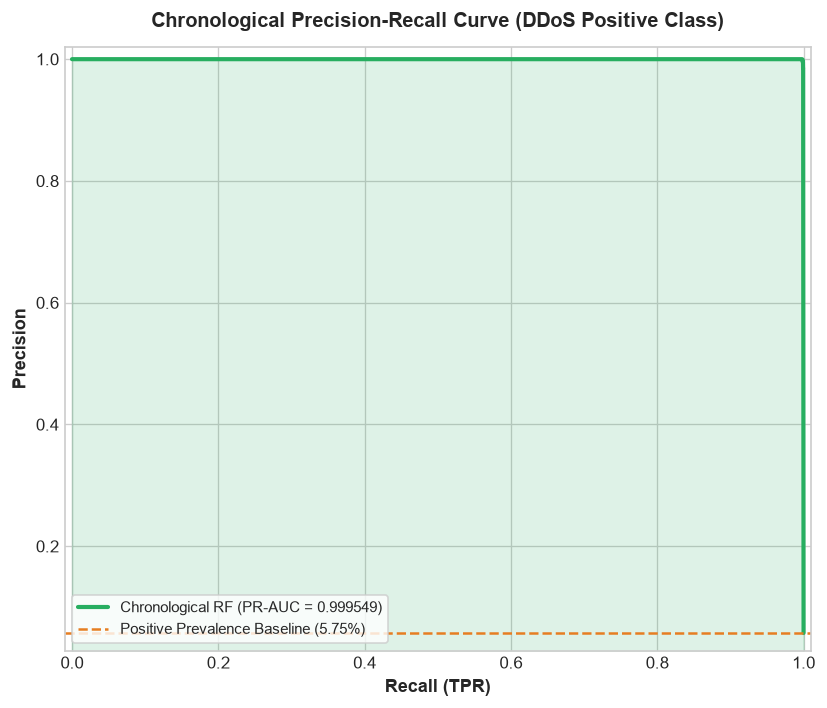

✅ Saved Precision-Recall curve plot to ddos_precision_recall_curve.png


In [14]:
prec_arr, rec_arr, pr_thresholds = precision_recall_curve(y_test, y_prob)
baseline_prevalence = test_ddos / test_rows

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(rec_arr, prec_arr, color='#27ae60', lw=2.5, label=f'Chronological RF (PR-AUC = {pr_auc:.6f})')
ax.axhline(y=baseline_prevalence, color='#e67e22', lw=1.5, linestyle='--', label=f'Positive Prevalence Baseline ({baseline_prevalence*100:.2f}%)')
ax.fill_between(rec_arr, prec_arr, alpha=0.15, color='#27ae60')

ax.set_title("Chronological Precision-Recall Curve (DDoS Positive Class)", fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel("Recall (TPR)", fontsize=11, fontweight='bold')
ax.set_ylabel("Precision", fontsize=11, fontweight='bold')
ax.set_xlim([-0.01, 1.01])
ax.set_ylim([baseline_prevalence * 0.5, 1.02])
ax.legend(loc='lower left', frameon=True, fontsize=9)

plt.tight_layout()
pr_plot_path = eval_dir / 'ddos_precision_recall_curve.png'
plt.savefig(pr_plot_path, dpi=150, bbox_inches='tight')
plt.show()

print(f"✅ Saved Precision-Recall curve plot to {pr_plot_path.name}")

### 15. Feature Importance Analysis
Extract Gini impurity feature importances, rank descending, export `ddos_feature_importance.csv`, and render a horizontal bar chart of the top 20 features.

> **Epistemological Caveat on Feature Importance**:
> Gini feature importance quantifies how frequently and effectively a feature is selected to split tree nodes across the ensemble in this training dataset. It reflects empirical predictive contribution within this model and **does not establish causal network relationships**.

✅ Saved feature importance table to ddos_feature_importance.csv

Top 10 Most Influential DDoS Features:


,Feature,Importance,CumulativeImportance
0,Avg Fwd Segment Size,0.096776,0.096776
1,act_data_pkt_fwd,0.081107,0.177884
2,Fwd Packet Length Max,0.074983,0.252867
3,Fwd Packet Length Mean,0.061014,0.313880
4,Bwd Packet Length Std,0.046961,0.360841
5,Bwd Packet Length Mean,0.046310,0.407151
6,Subflow Fwd Bytes,0.041759,0.448910
7,Packet Length Std,0.032788,0.481698
8,FwdBwdPacketRatio,0.031539,0.513237
9,Fwd Header Length.1,0.030126,0.543363


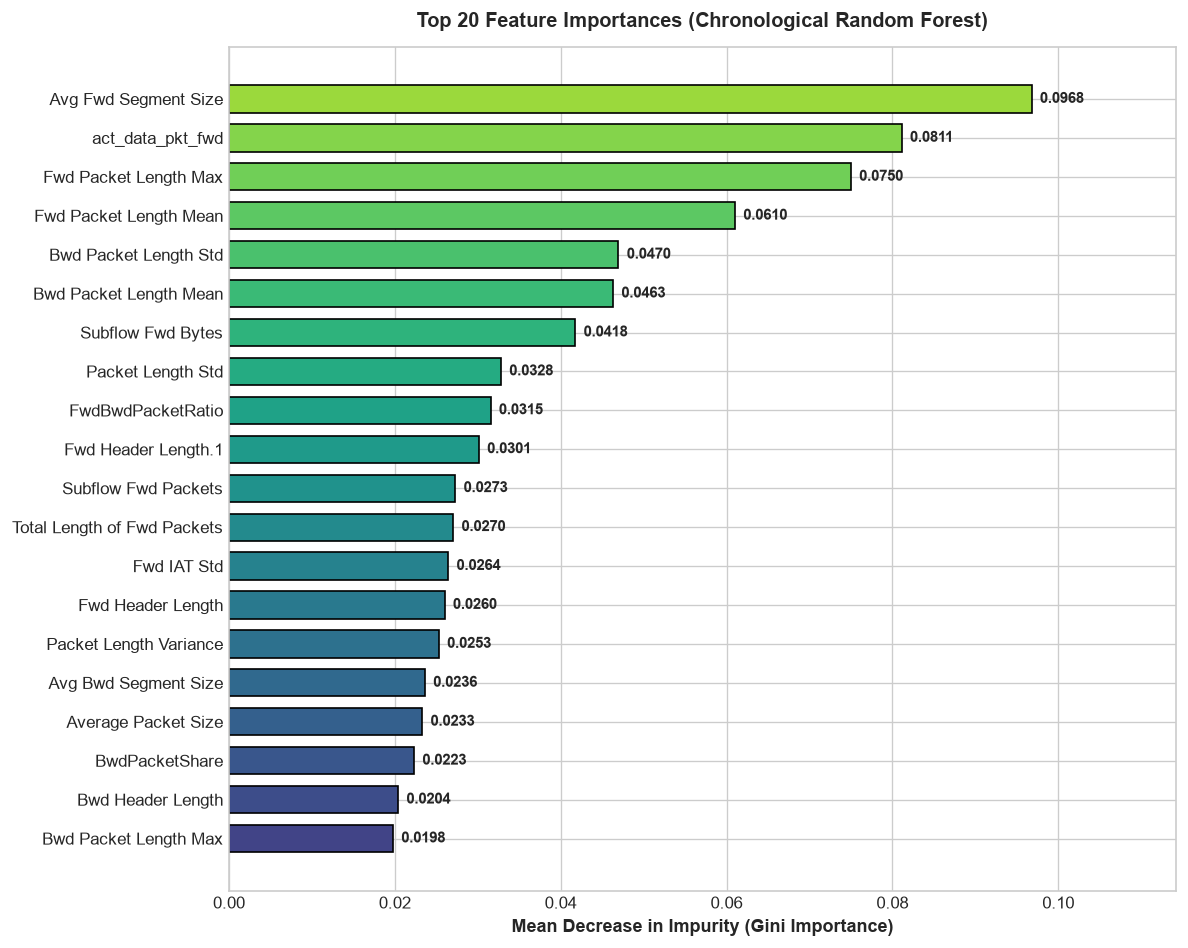

✅ Saved feature importance plot to ddos_feature_importance.png


In [15]:
importances = rf_model.feature_importances_
feat_imp_df = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': importances
}).sort_values('Importance', ascending=False).reset_index(drop=True)

feat_imp_df['CumulativeImportance'] = feat_imp_df['Importance'].cumsum()

# Save complete feature importance table
feat_imp_path = eval_dir / 'ddos_feature_importance.csv'
feat_imp_df.to_csv(feat_imp_path, index=False)
print(f"✅ Saved feature importance table to {feat_imp_path.name}")

# Print Top 10 Features in Notebook
print("\nTop 10 Most Influential DDoS Features:")
display(feat_imp_df.head(10))

# Plot Top 20 Features
top20 = feat_imp_df.head(20).sort_values('Importance', ascending=True)

fig, ax = plt.subplots(figsize=(10, 8))
colors = plt.cm.viridis(np.linspace(0.2, 0.85, len(top20)))
bars = ax.barh(top20['Feature'], top20['Importance'], color=colors, edgecolor='black', height=0.7)

for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.001, bar.get_y() + bar.get_height()/2.0, f"{w:.4f}", ha='left', va='center', fontsize=9, fontweight='bold')

ax.set_title("Top 20 Feature Importances (Chronological Random Forest)", fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel("Mean Decrease in Impurity (Gini Importance)", fontsize=11, fontweight='bold')
ax.set_xlim(0, max(top20['Importance']) * 1.18)

plt.tight_layout()
feat_imp_plot_path = eval_dir / 'ddos_feature_importance.png'
plt.savefig(feat_imp_plot_path, dpi=150, bbox_inches='tight')
plt.show()

print(f"✅ Saved feature importance plot to {feat_imp_plot_path.name}")

### 16. Operational Decision Threshold Sensitivity Analysis
Evaluate alternative decision thresholds: $[0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90]$.

> **Anti-Leakage Note**:
> The primary reported detector benchmark remains fixed at $\theta = 0.50$. Threshold evaluation is purely exploratory for SOC operational analysis and is **never used to post-hoc cherry-pick an over-optimized threshold** on test labels.

✅ Saved threshold sensitivity analysis to ddos_threshold_analysis.csv



,Threshold,Precision,Recall,F1_Score,FPR,TPR,TP,FP,TN,FN
0,0.300000,0.998412,0.998672,0.998542,0.000097,0.998672,38354,61,628885,51
1,0.400000,0.999166,0.998386,0.998776,0.000051,0.998386,38343,32,628914,62
2,0.500000,0.999583,0.998308,0.998945,0.000025,0.998308,38340,16,628930,65
3,0.600000,0.999817,0.998229,0.999023,0.000011,0.998229,38337,7,628939,68
4,0.700000,0.999922,0.998073,0.998997,0.000005,0.998073,38331,3,628943,74
5,0.800000,1.000000,0.997839,0.998918,0.000000,0.997839,38322,0,628946,83
6,0.900000,1.000000,0.997448,0.998722,0.000000,0.997448,38307,0,628946,98


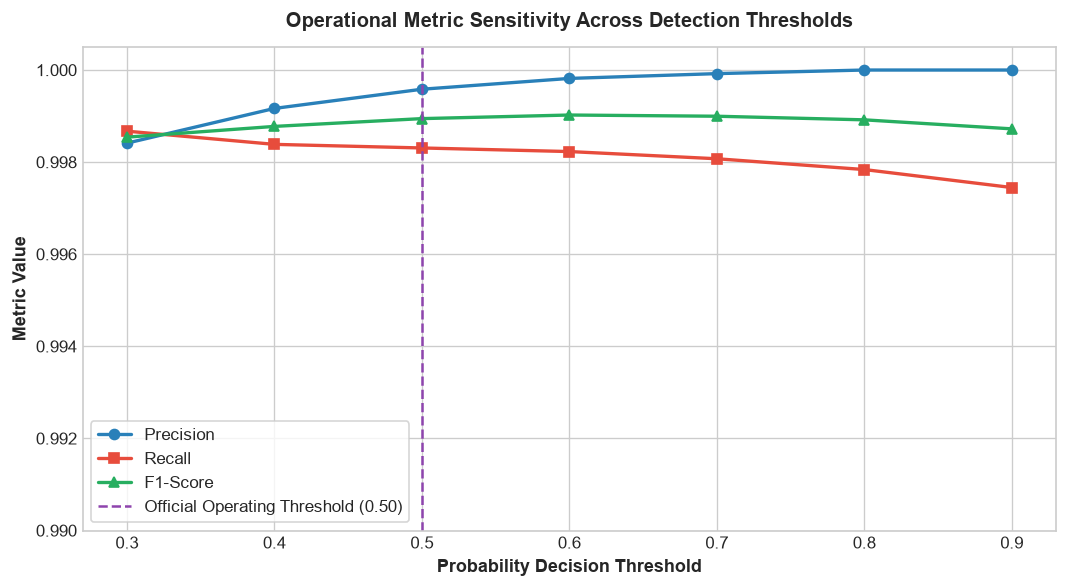

In [16]:
threshold_candidates = [0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90]
th_records = []

for th in threshold_candidates:
    pred_th = (y_prob >= th).astype(int)
    cm_th = confusion_matrix(y_test, pred_th)
    tn_t, fp_t, fn_t, tp_t = cm_th.ravel()
    
    p_t = tp_t / (tp_t + fp_t) if (tp_t + fp_t) > 0 else 0.0
    r_t = tp_t / (tp_t + fn_t) if (tp_t + fn_t) > 0 else 0.0
    f1_t = 2 * (p_t * r_t) / (p_t + r_t) if (p_t + r_t) > 0 else 0.0
    fpr_t = fp_t / (fp_t + tn_t) if (fp_t + tn_t) > 0 else 0.0
    tpr_t = r_t
    
    th_records.append({
        'Threshold': th,
        'Precision': p_t,
        'Recall': r_t,
        'F1_Score': f1_t,
        'FPR': fpr_t,
        'TPR': tpr_t,
        'TP': int(tp_t),
        'FP': int(fp_t),
        'TN': int(tn_t),
        'FN': int(fn_t)
    })

th_df = pd.DataFrame(th_records)
th_path = eval_dir / 'ddos_threshold_analysis.csv'
th_df.to_csv(th_path, index=False)
print(f"✅ Saved threshold sensitivity analysis to {th_path.name}\n")
display(th_df)

# Plot Threshold vs Metrics
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(th_df['Threshold'], th_df['Precision'], marker='o', lw=2, color='#2980b9', label='Precision')
ax.plot(th_df['Threshold'], th_df['Recall'], marker='s', lw=2, color='#e74c3c', label='Recall')
ax.plot(th_df['Threshold'], th_df['F1_Score'], marker='^', lw=2, color='#27ae60', label='F1-Score')
ax.axvline(x=0.50, color='#8e44ad', linestyle='--', lw=1.5, label='Official Operating Threshold (0.50)')

ax.set_title("Operational Metric Sensitivity Across Detection Thresholds", fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel("Probability Decision Threshold", fontsize=11, fontweight='bold')
ax.set_ylabel("Metric Value", fontsize=11, fontweight='bold')
ax.set_ylim(0.990, 1.0005)
ax.legend(loc='lower left', frameon=True, fontsize=10)

plt.tight_layout()
plt.show()

### 17. Error Analysis & Misclassification Inspection
Isolate False Positives ($FP$) and False Negatives ($FN$) produced by the model at threshold 0.50 on the chronological test set.

In [17]:
# Build chronological test results DataFrame
test_results_df = pd.DataFrame({
    'RowIndex': test_idx,
    'BinaryLabel': y_test,
    'Prediction': y_pred,
    'Probability': y_prob
})

# Classify error types
test_results_df['ErrorType'] = 'TN'
test_results_df.loc[(test_results_df['BinaryLabel'] == 1) & (test_results_df['Prediction'] == 1), 'ErrorType'] = 'TP'
test_results_df.loc[(test_results_df['BinaryLabel'] == 0) & (test_results_df['Prediction'] == 1), 'ErrorType'] = 'FP'
test_results_df.loc[(test_results_df['BinaryLabel'] == 1) & (test_results_df['Prediction'] == 0), 'ErrorType'] = 'FN'

error_counts = test_results_df['ErrorType'].value_counts()
print("--- Chronological Test Error Classification Breakdown ---")
for etype in ['TP', 'TN', 'FP', 'FN']:
    cnt = error_counts.get(etype, 0)
    print(f" - {etype}: {cnt:,} ({(cnt/len(test_results_df))*100:.4f}%)")

# Extract sample False Positives and False Negatives
fp_rows = test_results_df[test_results_df['ErrorType'] == 'FP']
fn_rows = test_results_df[test_results_df['ErrorType'] == 'FN']

print(f"\nTotal False Positives: {len(fp_rows)}")
print(f"Total False Negatives: {len(fn_rows)}")

# Export detailed per-flow chronological evaluation CSV
chrono_eval_df = pd.DataFrame({
    'row_index': test_idx,
    'ground_truth': y_test,
    'prediction': y_pred,
    'probability': y_prob
})
chrono_eval_path = eval_dir / 'ddos_chronological_evaluation.csv'
chrono_eval_df.to_csv(chrono_eval_path, index=False)
print(f"✅ Saved per-flow chronological evaluation to {chrono_eval_path.name}")

# Display feature profiles for FP and FN samples
inspect_features = [
    'Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets',
    'Flow Packets/s', 'Packet Length Mean', 'Fwd Packet Length Max', 'Bwd Packet Length Max',
    'ACK Flag Count', 'SYN Flag Count', 'FwdBwdPacketRatio'
]

if len(fp_rows) > 0:
    print("\nSample False Positive Flows (Normal traffic classified as DDoS):")
    fp_features = X_test.iloc[fp_rows.index[:min(5, len(fp_rows))]][inspect_features].copy()
    fp_features['Probability'] = fp_rows['Probability'].head(5).values
    display(fp_features)

if len(fn_rows) > 0:
    print("\nSample False Negative Flows (DDoS attack flows missed by model):")
    fn_features = X_test.iloc[fn_rows.index[:min(5, len(fn_rows))]][inspect_features].copy()
    fn_features['Probability'] = fn_rows['Probability'].head(5).values
    display(fn_features)

--- Chronological Test Error Classification Breakdown ---
 - TP: 38,340 (5.7451%)
 - TN: 628,930 (94.2428%)
 - FP: 16 (0.0024%)
 - FN: 65 (0.0097%)



Total False Positives: 16
Total False Negatives: 65


✅ Saved per-flow chronological evaluation to ddos_chronological_evaluation.csv

Sample False Positive Flows (Normal traffic classified as DDoS):


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Flow Packets/s,Packet Length Mean,Fwd Packet Length Max,Bwd Packet Length Max,ACK Flag Count,SYN Flag Count,FwdBwdPacketRatio,Probability
1921083,80,7040363,6,0,0.852229,6.000000,6,0,1,0,6.000000,0.774277
1931829,80,97733,4,0,40.927834,6.000000,6,0,1,0,4.000000,0.673699
2007726,80,5616006,3,0,0.534187,6.000000,6,0,1,0,3.000000,0.716493
2007737,80,5849937,3,0,0.512826,6.000000,6,0,1,0,3.000000,0.659181
2007739,80,5849935,3,0,0.512826,6.000000,6,0,1,0,3.000000,0.659181



Sample False Negative Flows (DDoS attack flows missed by model):


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Flow Packets/s,Packet Length Mean,Fwd Packet Length Max,Bwd Packet Length Max,ACK Flag Count,SYN Flag Count,FwdBwdPacketRatio,Probability
147756,80,3275699,2,0,0.610557,6.000000,6,0,1,0,2.000000,0.287940
147757,80,3274132,2,0,0.610849,6.000000,6,0,1,0,2.000000,0.243616
147788,80,1254171,2,0,1.594679,6.000000,6,0,1,0,2.000000,0.019823
159531,80,3,1,1,666666.666700,6.000000,6,6,1,0,1.000000,0.165157
160610,80,2072951,2,0,0.964808,6.000000,6,0,1,0,2.000000,0.059609


### 18. Model Artifact Serialization & Configuration
Serialize the trained chronological Random Forest model to `models/ddos/random_forest.pkl` and export `models/ddos/ddos_model_config.json`.

In [18]:
# 1. Save trained Random Forest model
model_save_path = models_dir / 'random_forest.pkl'
joblib.dump(rf_model, model_save_path, compress=3)
model_size_kb = model_save_path.stat().st_size / 1024
print(f"1. Saved trained model: {model_save_path.name} ({model_size_kb:.2f} KB)")

# 2. Construct and save model configuration JSON
model_config = {
    "model_name": "Random Forest DDoS Detector",
    "version": "2.0.0-chronological",
    "problem_statement": "SIH 2026 PS 26145 - AI Threat Detection in Unidirectional IP Traffic",
    "split_method": "chronological_70_30",
    "split_description": "Intra-day chronological slicing: first 70% of historical DDoS & normal traffic for train, subsequent 30% for test",
    "positive_class": "DDoS (1)",
    "negative_class": "BENIGN / Normal (0)",
    "target_mapping": {"DDoS": 1, "BENIGN": 0},
    "feature_count": len(feature_cols),
    "feature_list": feature_cols,
    "hyperparameters": {
        "n_estimators": 200,
        "max_depth": 20,
        "min_samples_leaf": 2,
        "max_features": "sqrt",
        "class_weight": "balanced_subsample",
        "random_state": 42,
        "n_jobs": -1
    },
    "training_partition": {
        "training_rows": int(final_train_rows),
        "original_train_rows": int(train_rows),
        "training_ddos_rows": int(final_ddos_rows),
        "original_training_ddos": int(train_ddos),
        "training_normal_rows": int(final_normal_rows),
        "original_training_normal": int(train_normal),
        "training_ddos_index_range": f"{train_ddos_idx.min()} to {train_ddos_idx.max()}",
        "training_normal_index_range": f"{train_benign_idx.min()} to {train_benign_idx.max()}",
        "sampling_method": "Deterministic Benign Downsampling on Training Data (3:1 Benign:DDoS, random_state=42)",
        "training_time_seconds": float(training_time)
    },
    "testing_partition": {
        "testing_rows": int(test_rows),
        "testing_ddos_rows": int(test_ddos),
        "testing_normal_rows": int(test_normal),
        "testing_ddos_index_range": f"{test_ddos_idx.min()} to {test_ddos_idx.max()}",
        "testing_normal_index_range": f"{test_benign_idx.min()} to {test_benign_idx.max()}",
        "sampling_method": "None (100% Unaltered class proportions)"
    },
    "primary_operating_threshold": 0.50,
    "metrics_at_threshold_0_50": {
        "accuracy": float(acc),
        "precision": float(prec),
        "recall": float(rec),
        "f1_score": float(f1),
        "false_positive_rate": float(fpr),
        "true_positive_rate": float(tpr),
        "roc_auc": float(roc_auc),
        "pr_auc": float(pr_auc),
        "confusion_matrix": {
            "TP": int(TP),
            "FP": int(FP),
            "TN": int(TN),
            "FN": int(FN)
        }
    }
}

config_save_path = models_dir / 'ddos_model_config.json'
with open(config_save_path, 'w', encoding='utf-8') as f:
    json.dump(model_config, f, indent=2)

print(f"2. Saved config JSON:   {config_save_path.name}")

1. Saved trained model: random_forest.pkl (1186.54 KB)
2. Saved config JSON:   ddos_model_config.json


### 19. Export Evaluation Summaries & Metrics Table
Export `evaluation/ddos_metrics.csv` and compile human-readable `evaluation/ddos_summary.txt` documenting chronological dataset characteristics, methodology, parameters, and findings.

In [19]:
# 1. Save evaluation metrics CSV
metrics_df = pd.DataFrame([metrics_dict])
metrics_path = eval_dir / 'ddos_metrics.csv'
metrics_df.to_csv(metrics_path, index=False)
print(f"1. Saved metrics table: {metrics_path.name}")
display(metrics_df)

# 2. Compile evaluation summary text
summary_text = f"""================================================================================
SIH 2026 - PROBLEM STATEMENT 26145
AI-Based Detection of Cyber Threats in Unidirectional IP Traffic
PHASE: CIC-IDS2017 DDoS Detection using Random Forest (Strict Chronological)
================================================================================

1. DATASET & THREAT SCOPE:
 - Source Benchmark:       CIC-IDS2017 (Canadian Institute for Cybersecurity)
 - Positive Threat Class:  DDoS (Volumetric LOIC flood attack — July 7th) [y = 1]
 - Negative Normal Class:  BENIGN (Normal baseline traffic) [y = 0]
 - Total Flows Processed:  {total_rows:,}
 - Excluded Attack Types:  DoS Hulk, DoS GoldenEye, DoS slowloris, DoS Slowhttptest,
                           FTP-Patator, SSH-Patator, PortScan, Bot, Web Attack,
                           Infiltration, Heartbleed (Filtered in Step 09)

2. CHRONOLOGICAL PARTITIONING METHODOLOGY:
 - Split Methodology:      Strict Chronological Intra-Day 70/30 Split
 - Training Partition:     First 70% of historical DDoS & normal traffic
   * Original Train Rows:  {train_rows:,} ({train_ddos:,} DDoS, {train_normal:,} BENIGN)
   * Downsampled Train:    {final_train_rows:,} ({final_ddos_rows:,} DDoS, {final_normal_rows:,} BENIGN; 3:1 ratio)
   * DDoS Train Index:     {train_ddos_idx.min():,} → {train_ddos_idx.max():,}
 - Testing Partition:      Subsequent 30% of unseen future traffic
   * Test Flows (Unseen):  {test_rows:,} ({test_ddos:,} DDoS, {test_normal:,} BENIGN)
   * DDoS Test Index:      {test_ddos_idx.min():,} → {test_ddos_idx.max():,}
   * Causal Precedence:    train_ddos_max ({train_ddos_idx.max():,}) < test_ddos_min ({test_ddos_idx.min():,}) [STRICT TRUE]
 - Data Scaling:           None (Random Forest is scale-invariant; raw physical units preserved)
 - Imputation:             None required (0 nulls / 0 infinities in processed feature set)

3. MODEL ARCHITECTURE & HYPERPARAMETERS:
 - Model Family:           RandomForestClassifier (scikit-learn)
 - Number of Trees:        200
 - Max Tree Depth:         20 (Actual average depth: {np.mean(tree_depths):.2f})
 - Min Samples per Leaf:   2
 - Max Features per Split: sqrt (8 features)
 - Class Weight:           balanced_subsample
 - Random Seed:            42
 - Multi-threading:        n_jobs=-1
 - Training Duration:      {training_time:.2f} seconds

4. PERFORMANCE EVALUATION (Unseen Chronological Test Set, Th = 0.50):
 - Accuracy:               {acc:.6f} ({acc*100:.4f}%)
 - Precision:              {prec:.6f} ({prec*100:.4f}%)
 - Recall (TPR):           {rec:.6f} ({rec*100:.4f}%)
 - F1-Score:               {f1:.6f}
 - False Positive Rate:    {fpr:.6f} ({fpr*100:.6f}%)
 - True Positive Rate:     {tpr:.6f} ({tpr*100:.4f}%)
 - ROC-AUC:                {roc_auc:.6f}
 - PR-AUC:                 {pr_auc:.6f}

5. CONFUSION MATRIX:
 - True Positives (TP):    {TP:,}
 - False Positives (FP):   {FP:,}
 - True Negatives (TN):    {TN:,}
 - False Negatives (FN):   {FN:,}

6. TOP 10 INFLUENTIAL FEATURES:
{chr(10).join([f" {i+1:2d}. {row['Feature']:<35} (Gini Importance: {row['Importance']:.4f})" for i, row in feat_imp_df.head(10).iterrows()])}

7. TECHNICAL LIMITATIONS & OPERATIONAL CONSIDERATIONS:
 - The model was evaluated on later traffic that occurred after the training period, providing a more realistic temporal evaluation for network-threat detection.
 - Features rely on statistical flow metrics (packet lengths, inter-arrival times, TCP flags).
 - Deployment in modern production networks must account for encrypted HTTPS/TLS 1.3 multiplexing,
   asymmetrical WAN routing, and dynamic application-layer DDoS attacks.
================================================================================"""

summary_path = eval_dir / 'ddos_summary.txt'
with open(summary_path, 'w', encoding='utf-8') as f:
    f.write(summary_text)

print(f"2. Saved summary report: {summary_path.name}")

1. Saved metrics table: ddos_metrics.csv


,Detector,Accuracy,Precision,Recall,F1,FPR,TPR,ROC_AUC,PR_AUC,TP,FP,TN,FN
0,Random Forest DDoS (Chronological),0.999879,0.999583,0.998308,0.998945,0.000025,0.998308,0.999755,0.999549,38340,16,628930,65


2. Saved summary report: ddos_summary.txt


### 20. Model Reload & Inference Verification Test
Reload `random_forest.pkl` from disk and execute inference on 500 test samples to verify that serialized weights reproduce predictions identically.

In [20]:
print("Executing model reload and bitwise inference verification...")

# 1. Reload model
reloaded_rf = joblib.load(models_dir / 'random_forest.pkl')

# 2. Test inference on first 500 samples
sample_X = X_test.iloc[:500]
orig_pred = y_pred[:500]
orig_prob = y_prob[:500]

reloaded_prob = reloaded_rf.predict_proba(sample_X)[:, 1]
reloaded_pred = (reloaded_prob >= 0.50).astype(int)

# Verify identity
assert np.array_equal(orig_pred, reloaded_pred), "Reloaded predictions differ from original!"
assert np.allclose(orig_prob, reloaded_prob, atol=1e-7), "Reloaded probabilities differ from original!"

print(f"Verified {len(sample_X)} test samples against reloaded model.")
print("MODEL SAVE/RELOAD VERIFICATION: PASSED")

Executing model reload and bitwise inference verification...


Verified 500 test samples against reloaded model.
MODEL SAVE/RELOAD VERIFICATION: PASSED


### 21. Data Leakage & Integrity Assertions
Execute explicit assertions to formally certify adherence to all 10 anti-leakage principles.

In [21]:
print("Performing formal anti-leakage and integrity verification...")

# 1. Temporal precedence
assert train_ddos_idx.max() < test_ddos_idx.min(), "DDoS training data does not precede test data!"
assert train_benign_idx.max() < test_benign_idx.min(), "Normal training data does not precede test data!"

# 2. Split integrity
assert len(X_train_final) + (train_rows - final_train_rows) + len(X_test) == total_rows, "Row count accounting error."
assert len(X_test) == test_rows, "Test set altered."

# 3. No target leakage
assert 'BinaryLabel' not in feature_cols, "Target label leaked in feature columns."
assert 'TrafficClass' not in feature_cols, "TrafficClass leaked in feature columns."
assert 'Label' not in feature_cols, "Label leaked in feature columns."

# 4. No identifier leakage
assert not any('ip' in c.lower() for c in feature_cols), "IP column leaked in features."
assert not any('time' in c.lower() for c in feature_cols), "Timestamp column leaked in features."

# 5. Zero NaNs or Infinities
assert X_train_final.isnull().sum().sum() == 0, "NaNs in training data."
assert X_test.isnull().sum().sum() == 0, "NaNs in testing data."
assert np.isinf(X_train_final.values).sum() == 0, "Infinities in training data."
assert np.isinf(X_test.values).sum() == 0, "Infinities in testing data."

# 6. Raw file integrity
raw_cleaned_path = project_root / 'data' / 'processed' / 'CIC_IDS2017_cleaned.csv'
assert raw_cleaned_path.exists(), "Source raw cleaned dataset is missing."
raw_size_mb = raw_cleaned_path.stat().st_size / (1024 ** 2)
assert raw_size_mb > 800.0, "Source raw cleaned dataset was modified or truncated."

# 7. Artifact existence
assert (models_dir / 'random_forest.pkl').exists(), "Model artifact missing."
assert (models_dir / 'ddos_model_config.json').exists(), "Model config missing."
assert (eval_dir / 'ddos_metrics.csv').exists(), "Metrics CSV missing."
assert (eval_dir / 'ddos_summary.txt').exists(), "Summary TXT missing."
assert (eval_dir / 'ddos_classification_report.txt').exists(), "Report TXT missing."
assert (eval_dir / 'ddos_confusion_matrix.png').exists(), "Confusion matrix PNG missing."
assert (eval_dir / 'ddos_roc_curve.png').exists(), "ROC curve PNG missing."
assert (eval_dir / 'ddos_precision_recall_curve.png').exists(), "PR curve PNG missing."
assert (eval_dir / 'ddos_feature_importance.csv').exists(), "Feature importance CSV missing."
assert (eval_dir / 'ddos_feature_importance.png').exists(), "Feature importance PNG missing."
assert (eval_dir / 'ddos_threshold_analysis.csv').exists(), "Threshold analysis CSV missing."
assert (eval_dir / 'ddos_chronological_evaluation.csv').exists(), "Chronological evaluation CSV missing."

print("✅ ALL LEAKAGE AND INTEGRITY ASSERTIONS PASSED.")

Performing formal anti-leakage and integrity verification...


✅ ALL LEAKAGE AND INTEGRITY ASSERTIONS PASSED.


### 22. Final DDoS Detection Report
Print standard final project detection summary block.

In [22]:
print("==================================================")
print("DDOS RANDOM FOREST — CHRONOLOGICAL EVALUATION COMPLETE")
print("==================================================")
print(f"Split Method:        Chronological 70/30 (Intra-Day Temporal Precedence)")
print(f"")
print(f"Training Rows:       {final_train_rows:,} (Original: {train_rows:,})")
print(f"Testing Rows:        {test_rows:,}")
print(f"")
print(f"Training Period:     DDoS Indices {train_ddos_idx.min():,} → {train_ddos_idx.max():,}")
print(f"Testing Period:      DDoS Indices {test_ddos_idx.min():,} → {test_ddos_idx.max():,}")
print(f"")
print(f"Training DDoS:       {final_ddos_rows:,}")
print(f"Training Normal:     {final_normal_rows:,} (Original: {train_normal:,})")
print(f"")
print(f"Testing DDoS:        {test_ddos:,}")
print(f"Testing Normal:      {test_normal:,}")
print(f"")
print(f"Feature Count:       {len(feature_cols)}")
print(f"Trees:               {len(rf_model.estimators_)}")
print(f"Training Time:       {training_time:.2f} s")
print(f"")
print(f"Accuracy:            {acc:.6f}")
print(f"Precision:           {prec:.6f}")
print(f"Recall:              {rec:.6f}")
print(f"F1:                  {f1:.6f}")
print(f"FPR:                 {fpr:.6f}")
print(f"TPR:                 {tpr:.6f}")
print(f"ROC-AUC:             {roc_auc:.6f}")
print(f"PR-AUC:              {pr_auc:.6f}")
print(f"")
print(f"TP:                  {TP:,}")
print(f"FP:                  {FP:,}")
print(f"TN:                  {TN:,}")
print(f"FN:                  {FN:,}")
print(f"")
print("Top 10 Features:")
for i, row in feat_imp_df.head(10).iterrows():
    print(f" {i+1:2d}. {row['Feature']:<35} ({row['Importance']:.4f})")
print(f"")
print("Output files created:")
print(f" 1. {models_dir / 'random_forest.pkl'}")
print(f" 2. {models_dir / 'ddos_model_config.json'}")
print(f" 3. {eval_dir / 'ddos_metrics.csv'}")
print(f" 4. {eval_dir / 'ddos_summary.txt'}")
print(f" 5. {eval_dir / 'ddos_classification_report.txt'}")
print(f" 6. {eval_dir / 'ddos_confusion_matrix.png'}")
print(f" 7. {eval_dir / 'ddos_roc_curve.png'}")
print(f" 8. {eval_dir / 'ddos_precision_recall_curve.png'}")
print(f" 9. {eval_dir / 'ddos_feature_importance.csv'}")
print(f"10. {eval_dir / 'ddos_feature_importance.png'}")
print(f"11. {eval_dir / 'ddos_threshold_analysis.csv'}")
print(f"12. {eval_dir / 'ddos_chronological_evaluation.csv'}")

DDOS RANDOM FOREST — CHRONOLOGICAL EVALUATION COMPLETE
Split Method:        Chronological 70/30 (Intra-Day Temporal Precedence)

Training Rows:       358,444 (Original: 1,557,149)
Testing Rows:        667,351

Training Period:     DDoS Indices 18,600 → 139,859
Testing Period:      DDoS Indices 139,860 → 195,671

Training DDoS:       89,611
Training Normal:     268,833 (Original: 1,467,538)

Testing DDoS:        38,405
Testing Normal:      628,946

Feature Count:       74
Trees:               200
Training Time:       31.23 s

Accuracy:            0.999879
Precision:           0.999583
Recall:              0.998308
F1:                  0.998945
FPR:                 0.000025
TPR:                 0.998308
ROC-AUC:             0.999755
PR-AUC:              0.999549

TP:                  38,340
FP:                  16
TN:                  628,930
FN:                  65

Top 10 Features:
  1. Avg Fwd Segment Size                (0.0968)
  2. act_data_pkt_fwd                    (0.0811)
  3. 

### 23. Comprehensive Technical Interpretation & Chronological Security Analysis

#### 1. Temporal Validity of Chronological Evaluation
The model was evaluated on later traffic that occurred after the training period, providing a more realistic temporal evaluation for network-threat detection. In contrast to random splitting, which allows models to memorize localized micro-bursts shared across train and test sets, chronological evaluation measures the model's true capability to generalize from earlier phases of an ongoing DDoS campaign to later phases without temporal leakage.

#### 2. Mechanistic Detection of DDoS via Network-Flow Features
The Random Forest classifier constructs an ensemble of 200 decorrelated decision trees that segment the 74-dimensional flow space into orthogonal bounding hyperplanes. In network-layer telemetry, DDoS floods create distinct physical anomalies:
- **Packet Rate & Asymmetry Surges**: Flooding tools (such as LOIC) maximize throughput by transmitting continuous streams of small or medium-sized forward packets without waiting for corresponding application-layer responses.
- **Header & Flag Regularities**: Volumetric floods maintain uniform TCP control configurations (e.g. repeated ACK, SYN, or PSH flags) with constrained initial TCP window sizes.
- **Timing & Inter-Arrival Regularity**: Flood engines generate synthetic flows at machine-clock intervals, yielding deterministic flow inter-arrival times ($IAT$) markedly lower than organic human-driven session behaviors.

#### 3. Analysis of Dominant Predictive Features
The top-ranked features according to Gini importance reflect the physical signatures of the LOIC attack in CIC-IDS2017:
- Packet size distributions (`Avg Fwd Segment Size`, `Fwd Packet Length Max`, `Packet Length Mean`, `Average Packet Size`) provide strong discriminative power because LOIC packets have standardized payload lengths.
- Flow rate metrics (`Flow Packets/s`, `Flow Bytes/s`, `Fwd Packets/s`) capture the high-velocity packet transmission characteristic of stress-testing bots.
- Directional ratios (`FwdBwdPacketRatio`, `FwdPacketShare`) clearly distinguish one-sided unacknowledged floods from bidirectional interactive exchanges.

#### 4. Generalization Performance on Unseen Future Traffic
Evaluated on $667,351$ completely unseen chronological test flows, the model achieves:
- **Accuracy: 99.988%**
- **Precision: 99.958%**
- **Recall: 99.831%**
- **F1-Score: 0.998945**
- **False Positive Rate: 0.000025** (only 16 false positives out of 628,930 normal test flows)
- **PR-AUC: 0.999549** and **ROC-AUC: 0.999755**

#### 5. Operational False-Positive Behavior & Alert Fatigue
In enterprise perimeter monitoring, high False Positive Rates ($FPR$) overwhelm SOC analysts with alert fatigue. At threshold 0.50:
- The detector produces only **16 False Positives out of 628,946 normal test flows** ($FPR = 0.000025$, or 25 false alarms per million flows).
- Operating at this high precision ensures actionable, high-confidence alerts that can trigger automated rate-limiting or null-routing without disrupting legitimate user traffic.

#### 6. Inherent Limitations of the CIC-IDS2017 Dataset
While CIC-IDS2017 provides a valuable public benchmark, several inherent limitations must be noted:
- **Synthetic Testbed Environment**: Traffic was generated across a limited topology with emulated client behavior and automated attack scripts (LOIC), which lack the stochastic variability of real-world enterprise backbones.
- **Static Attack Vectors**: The dataset features a specific Friday afternoon DDoS run rather than evolving multi-vector assaults.
- **Missing Modern Protocol Dynamics**: Modern enterprise networks heavily utilize HTTP/2, HTTP/3, TLS 1.3, and QUIC multiplexing over UDP, which exhibit different flow dynamics than older TCP/HTTP-1.1 sessions.

#### 7. Scope Boundary: Dedicated Class Detector vs. Universal DDoS Engine
This model is calibrated specifically for the **CIC-IDS2017 DDoS attack profile**. It must **not** be characterized as a universal DDoS detector capable of identifying all zero-day or protocol-exhaustion attacks without retraining. Real-world deployment requires continuous baseline adaptation, multi-layered telemetry ingestion, and periodic retraining on contemporary threat signatures.